In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from warnings import filterwarnings
filterwarnings("ignore")

In [2]:
df = pd.read_csv(r"C:\Users\deytu\Desktop\study\EXCELR\Assignment\Data and Docs\diabetes_XGB.csv")
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### Observations 
- No Null Vlues are present 
- Since Glucose, BloodPressure, SkinThickness, Insulin and BMI cant be zero we need do discard the zero values

In [5]:
columns = ['Pregnancies', 'Glucose',  'DiabetesPedigreeFunction', 'Age', 'Outcome']

In [6]:
for col in columns:
    print(df[col].value_counts())
    

Pregnancies
1     135
0     111
2     103
3      75
4      68
5      57
6      50
7      45
8      38
9      28
10     24
11     11
13     10
12      9
14      2
15      1
17      1
Name: count, dtype: int64
Glucose
99     17
100    17
111    14
129    14
125    14
       ..
191     1
177     1
44      1
62      1
190     1
Name: count, Length: 136, dtype: int64
DiabetesPedigreeFunction
0.258    6
0.254    6
0.268    5
0.207    5
0.261    5
        ..
1.353    1
0.655    1
0.092    1
0.926    1
0.171    1
Name: count, Length: 517, dtype: int64
Age
22    72
21    63
25    48
24    46
23    38
28    35
26    33
27    32
29    29
31    24
41    22
30    21
37    19
42    18
33    17
38    16
36    16
32    16
45    15
34    14
46    13
43    13
40    13
39    12
35    10
50     8
51     8
52     8
44     8
58     7
47     6
54     6
49     5
48     5
57     5
53     5
60     5
66     4
63     4
62     4
55     4
67     3
56     3
59     3
65     3
69     2
61     2
72     1
81     1
64   

In [7]:
## removing zero value from columns which cant have zero as it is medically impractical 
columns_1 = [ 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin','BMI']
for col in columns_1:
    print(col)
    print((df[col]==0).sum())

Glucose
5
BloodPressure
35
SkinThickness
227
Insulin
374
BMI
11


In [8]:
df[columns_1] = df[columns_1].replace(0, np.nan)

In [9]:
df[columns_1].isnull().sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

<Axes: >

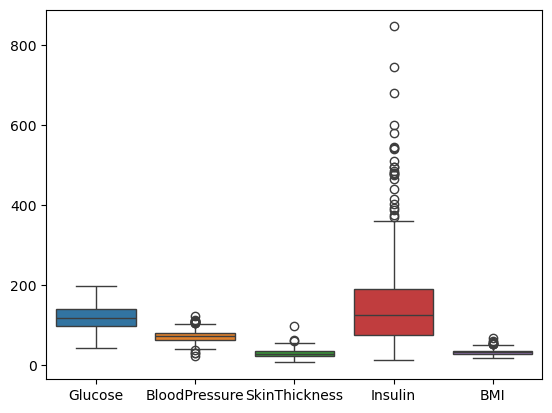

In [10]:
sns.boxplot(df[columns_1])

In [11]:
## since outliers are ptresent we will use median for imputation only foe glucose we will use mean 
columns_2 = ['BloodPressure', 'SkinThickness', 'Insulin','BMI']
for col in columns_2:
    df[col] = df[col].fillna(df[col].median())

In [12]:
df["Glucose"] = df["Glucose"].fillna(df["Glucose"].mean())


In [13]:
df[columns_1].isnull().sum()

Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

## Observations 
- Successfully removed impractical values 
- Now we will do data visualisation 

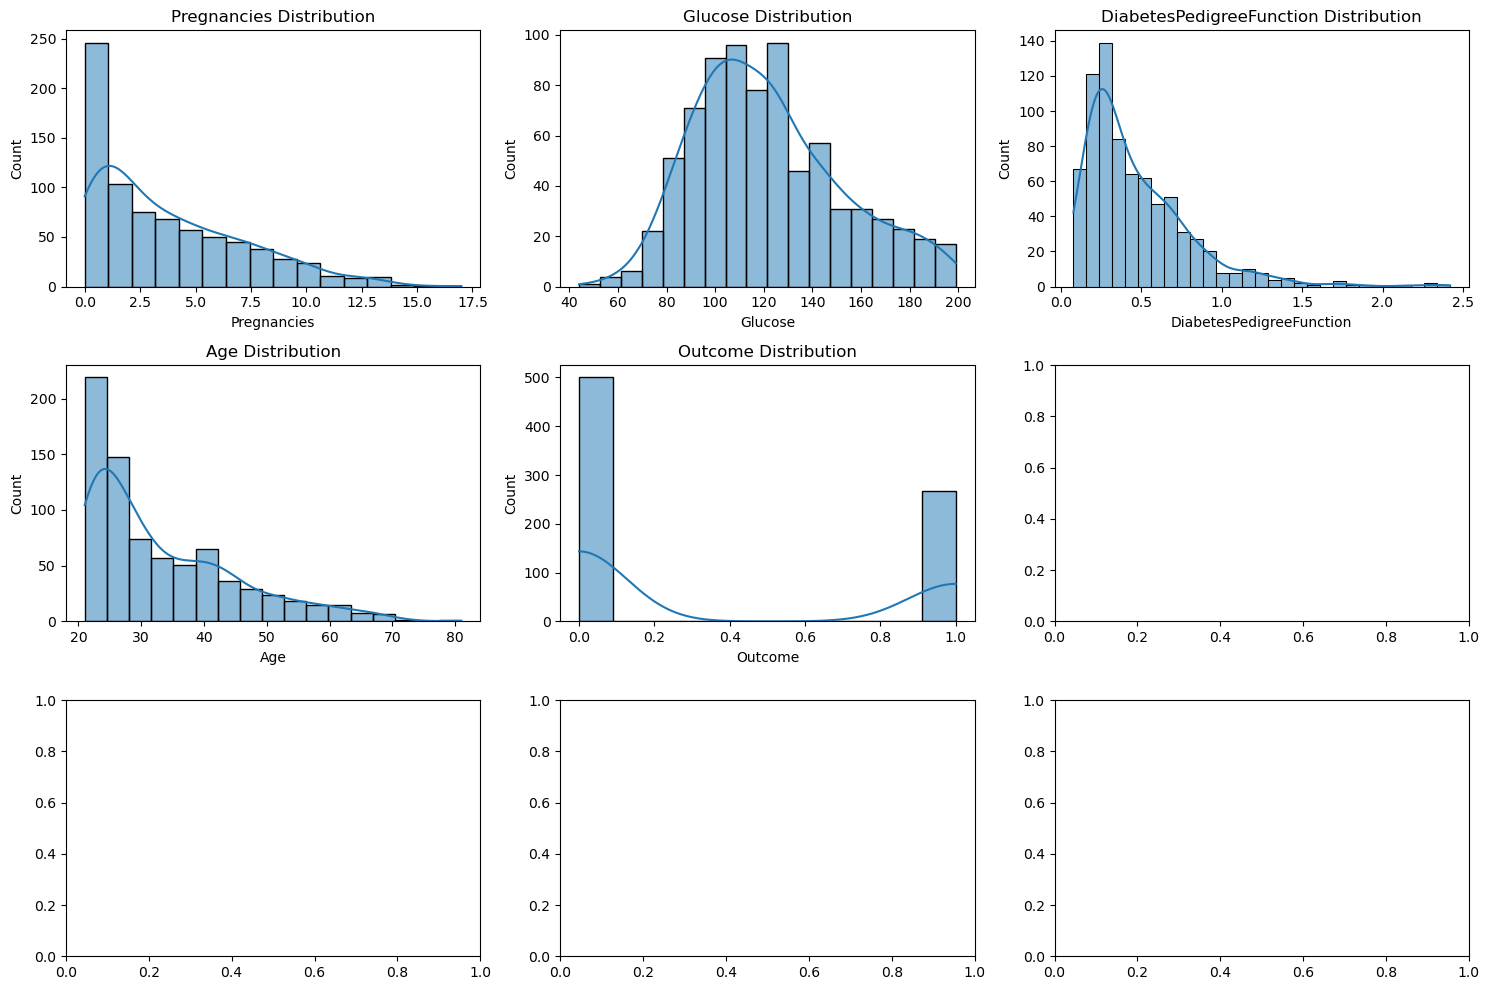

In [14]:
## histogram 
fig, axes = plt.subplots(3,3 , figsize = (15,10))
axes = axes.flatten()

for i,col in enumerate(columns):
    sns.histplot(data = df , x = col , kde = True , ax = axes[i])
    axes[i].set_title(f"{col} Distribution")
plt.tight_layout()
plt.show()
    

## Observation
- Glucose shows an approximately normal distribution with no major outliers.
- BloodPressure and BMI are also fairly normally distributed with some mild outliers.
- SkinThickness and Insulin are highly right-skewed and contain several extreme values.
- Pregnancies, DiabetesPedigreeFunction, and Age show right-skewed distributions.

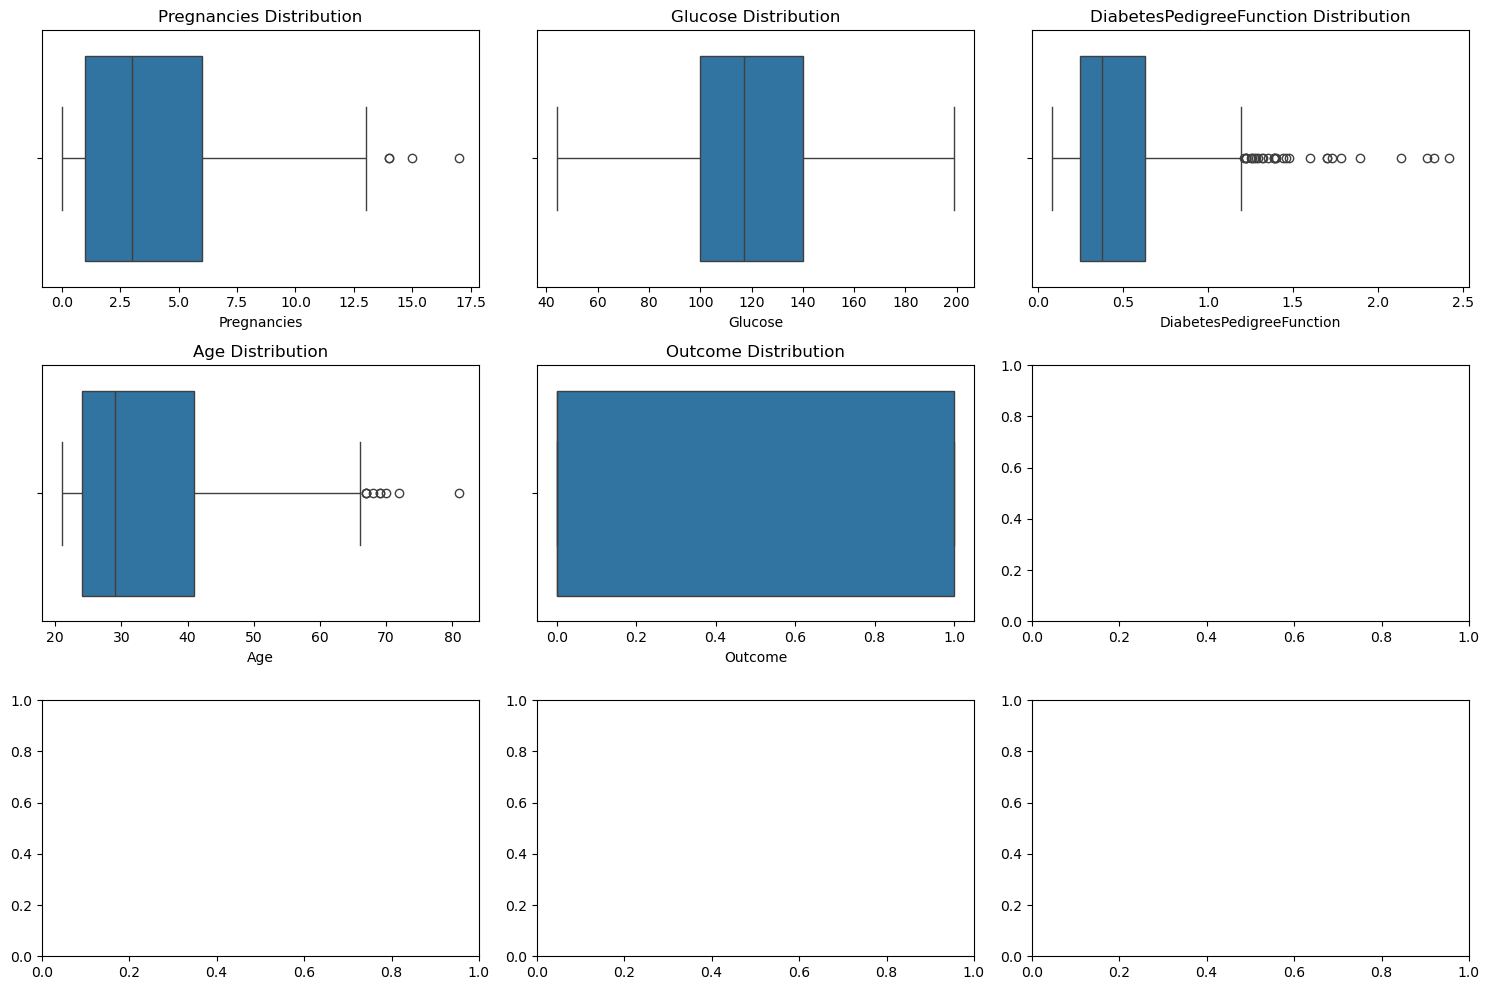

In [15]:
fig, axes = plt.subplots(3,3 , figsize = (15,10))
axes = axes.flatten()

for i,col in enumerate(columns):
    sns.boxplot(data = df, x = col, ax=axes[i] )
    axes[i].set_title(f"{col} Distribution")
plt.tight_layout()
plt.show()

In [16]:
df.corr()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.127911,0.208615,0.081770,0.025047,0.021559,-0.033523,0.544341,0.221898
Glucose,0.127911,1.000000,0.218557,0.192686,0.419064,0.231128,0.137060,0.266534,0.492928
BloodPressure,0.208615,0.218557,1.000000,0.191892,0.045363,0.281257,-0.002378,0.324915,0.165723
SkinThickness,0.081770,0.192686,0.191892,1.000000,0.155610,0.543205,0.102188,0.126107,0.214873
Insulin,0.025047,0.419064,0.045363,0.155610,1.000000,0.180241,0.126503,0.097101,0.203790
BMI,0.021559,0.231128,0.281257,0.543205,0.180241,1.000000,0.153438,0.025597,0.312038
DiabetesPedigreeFunction,-0.033523,0.137060,-0.002378,0.102188,0.126503,0.153438,1.000000,0.033561,0.173844
Age,0.544341,0.266534,0.324915,0.126107,0.097101,0.025597,0.033561,1.000000,0.238356
Outcome,0.221898,0.492928,0.165723,0.214873,0.203790,0.312038,0.173844,0.238356,1.000000


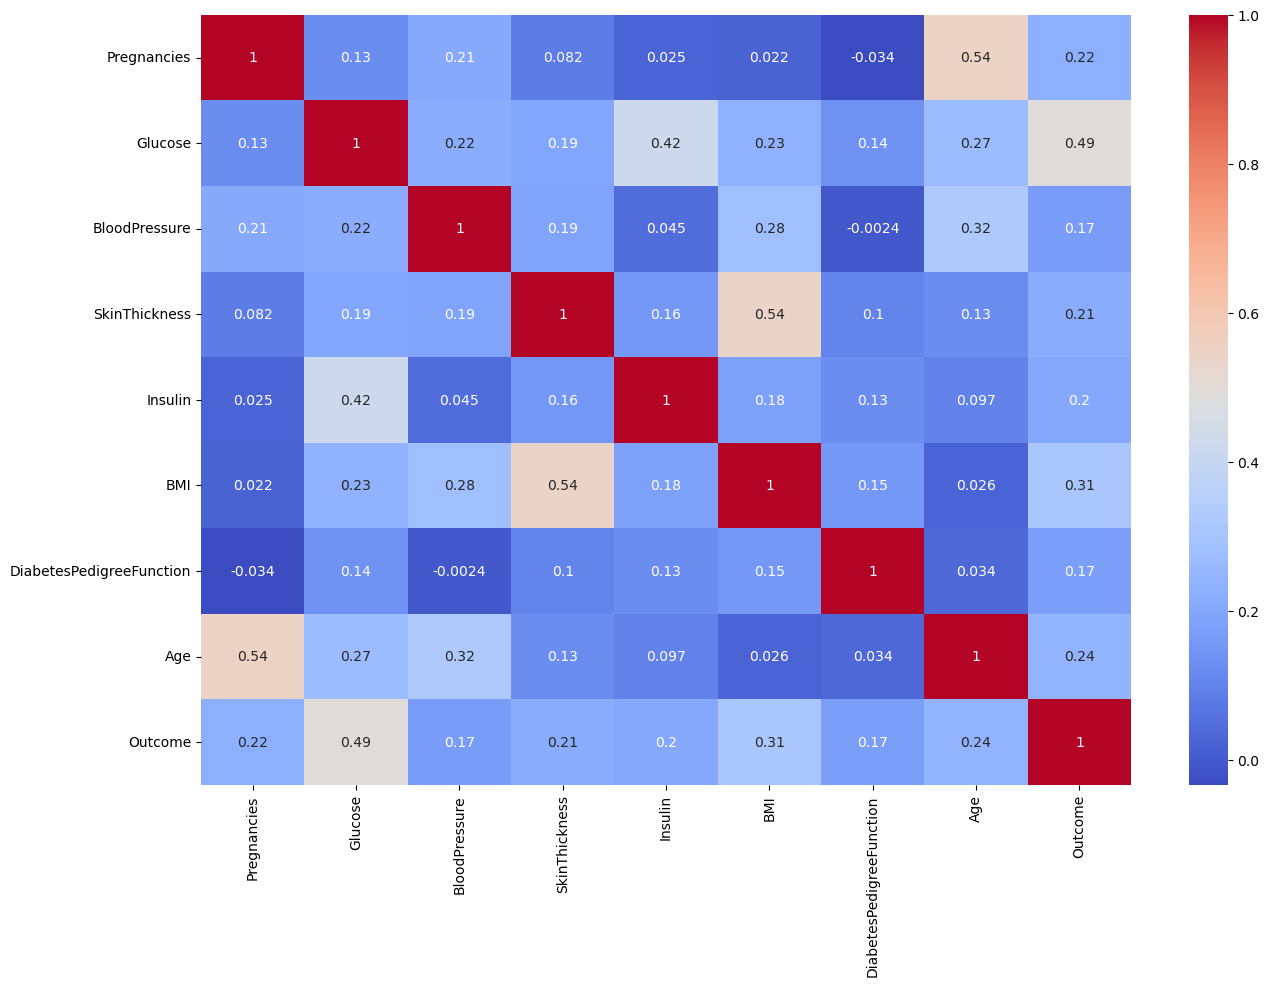

In [17]:
plt.figure(figsize = (15,10))
sns.heatmap(df.corr() , annot = True , cmap = "coolwarm")
plt.show()

### Correlation Observations

- Glucose has the strongest positive correlation with Outcome (0.493), making it the most important feature for diabetes prediction.
- BMI has a moderate positive correlation with Outcome (0.312), followed by Age (0.238) and Pregnancies (0.222).
- SkinThickness and BMI have the highest correlation among the predictor variables (0.543).
- Overall, there is no very high correlation between most predictor variables, suggesting that severe multicollinearity is not a major concern.

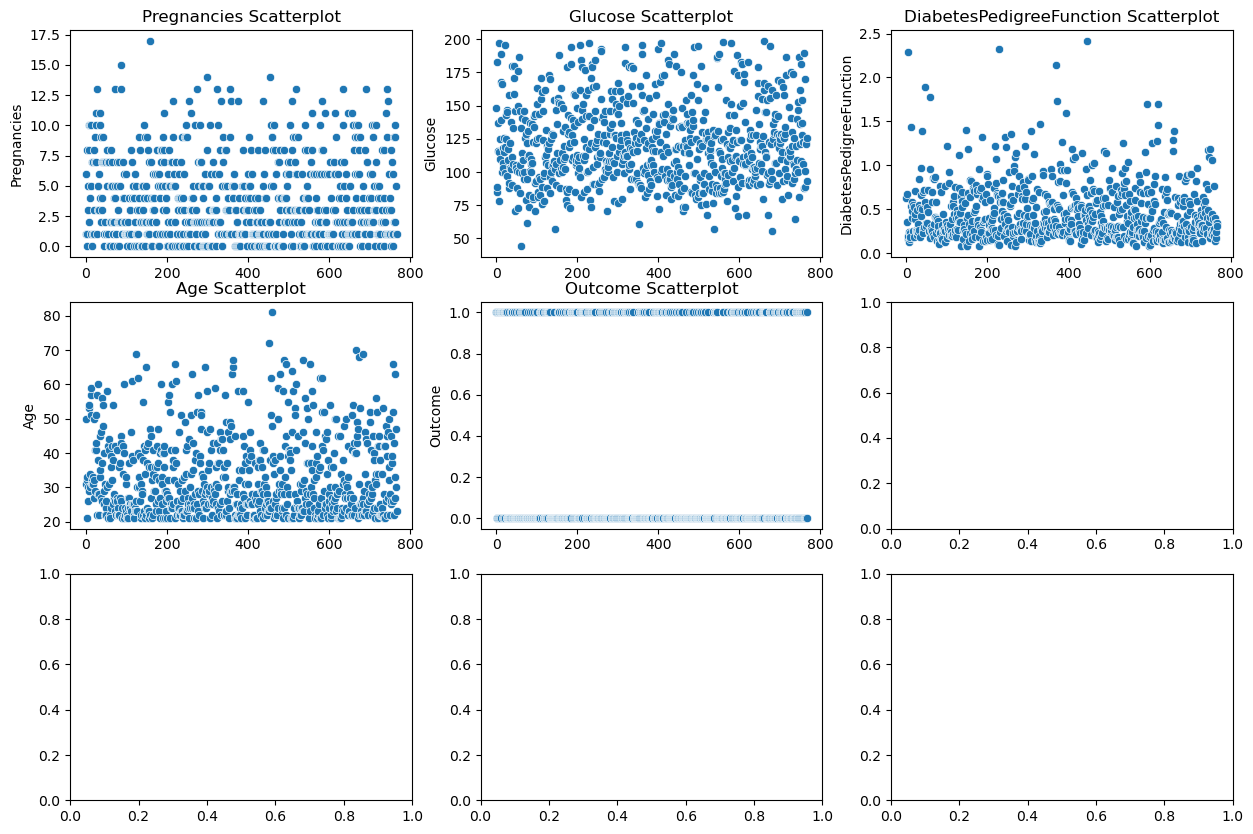

In [18]:
fig , axes = plt.subplots(3,3, figsize = (15,10))
axes = axes.flatten()

for i, col in enumerate(columns):
    sns.scatterplot(df[col] , ax = axes[i])
    axes[i].set_title(f"{col} Scatterplot")
plt.show()    

## Data Preproccesing 


- No encoding is required because all predictor variables are numerical.
- The `Outcome` variable is already binary, represented by 0 and 1.
- Therefore, the dataset can be directly used for machine learning models without label or one-hot encoding.

In [19]:
### Train Test split 
X = df.drop(columns="Outcome", axis = 1 )
y = df["Outcome"]
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
  X,y,test_size=0.2,random_state= 42 )
X_test

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
668,6,98.0,58.0,33.0,190.0,34.0,0.430,43
324,2,112.0,75.0,32.0,125.0,35.7,0.148,21
624,2,108.0,64.0,29.0,125.0,30.8,0.158,21
690,8,107.0,80.0,29.0,125.0,24.6,0.856,34
473,7,136.0,90.0,29.0,125.0,29.9,0.210,50
...,...,...,...,...,...,...,...,...
355,9,165.0,88.0,29.0,125.0,30.4,0.302,49
534,1,77.0,56.0,30.0,56.0,33.3,1.251,24
344,8,95.0,72.0,29.0,125.0,36.8,0.485,57
296,2,146.0,70.0,38.0,360.0,28.0,0.337,29


In [22]:
pip install xgboost 

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 12.8 MB/s eta 0:00:04
   -- ------------------------------------- 3.4/48.9 MB 16.0 MB/s eta 0:00:03
   ---- ----------------------------------- 5.2/48.9 MB 11.1 MB/s eta 0:00:04
   ----- ---------------------------------- 6.3/48.9 MB 8.8 MB/s eta 0:00:05
   ----- ---------------------------------- 6.6/48.9 MB 7.8 MB/s eta 0:00:06
   ----- ---------------------------------- 7.1/48.9 MB 6.3 MB/s eta 0:00:07
   ----- ---------------------------------- 7.3/48.9 MB 5.9 MB/s eta 0:00:08
   ------ --------------------------------- 7.9/48.9 MB 5.3 MB/s eta 0:00:08
   ------ --------------------------------- 8.4/48.9 MB 4.9 MB/s eta 0:00:09
   ------- -------------------------------- 8.9/48.9 MB 4.7 MB/s eta 0:00:09
   ------- -------------------------------- 9.4/48.9 MB 4.5 MB/s eta 0:00:09
   -------- ------------------------------- 10.2/48.9 MB 4.3 MB/s eta 0:00:09
  

XGBoost Accuracy: 0.7337662337662337

Confusion Matrix:
 [[77 22]
 [19 36]]

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.78      0.79        99
           1       0.62      0.65      0.64        55

    accuracy                           0.73       154
   macro avg       0.71      0.72      0.71       154
weighted avg       0.74      0.73      0.74       154



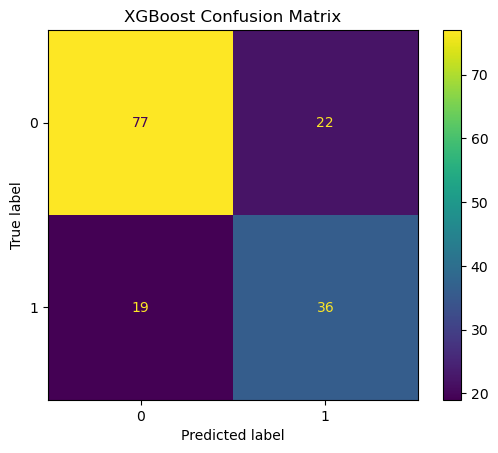

In [30]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))

# XGBoost
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_xgb)
plt.title("XGBoost Confusion Matrix")
plt.show()

In [24]:
pip install lightgbm


   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 11.4 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


LightGBM Accuracy: 0.7467532467532467

Confusion Matrix:
 [[79 20]
 [19 36]]

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.80      0.80        99
           1       0.64      0.65      0.65        55

    accuracy                           0.75       154
   macro avg       0.72      0.73      0.73       154
weighted avg       0.75      0.75      0.75       154



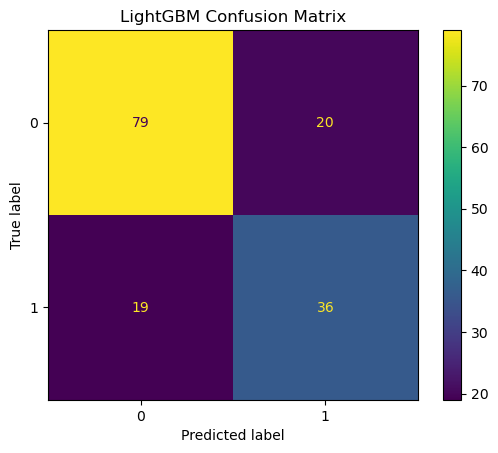

In [32]:
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

lgbm_model = LGBMClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    verbosity=-1
)

lgbm_model.fit(X_train, y_train)

y_pred_lgbm = lgbm_model.predict(X_test)

print("LightGBM Accuracy:", accuracy_score(y_test, y_pred_lgbm))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_lgbm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lgbm))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lgbm)
plt.title("LightGBM Confusion Matrix")
plt.show()

In [33]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

grid_xgb.fit(X_train, y_train)

print("Best Parameters:", grid_xgb.best_params_)
print("Best CV F1 Score:", grid_xgb.best_score_)





Best Parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best CV F1 Score: 0.6689390611302533


### XGBoost Hyperparameter Tuning Observations

- The best parameter combination was `learning_rate=0.1`, `max_depth=3`, `n_estimators=100`, and `subsample=0.8`.
- The model achieved a mean 5-fold cross-validation F1-score of approximately **0.669**.
- A maximum tree depth of 3 helps control model complexity and reduces the risk of overfitting.
- The CV F1-score provides a more reliable estimate of model performance than relying on a single train-test split.

In [27]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

lgbm = LGBMClassifier(
    random_state=42,
    verbosity=-1
)

param_grid_lgbm = {
    'n_estimators': [100, 200],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [15, 31],
    'subsample': [0.8, 1.0]
}

grid_lgbm = GridSearchCV(
    estimator=lgbm,
    param_grid=param_grid_lgbm,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

grid_lgbm.fit(X_train, y_train)

print("Best Parameters:", grid_lgbm.best_params_)
print("Best CV F1 Score:", grid_lgbm.best_score_)

Best Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'num_leaves': 15, 'subsample': 0.8}
Best CV F1 Score: 0.6549105255798967


In [28]:
from sklearn.metrics import accuracy_score, classification_report

best_xgb = grid_xgb.best_estimator_

y_pred = best_xgb.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Test Accuracy: 0.7402597402597403
              precision    recall  f1-score   support

           0       0.81      0.78      0.79        99
           1       0.63      0.67      0.65        55

    accuracy                           0.74       154
   macro avg       0.72      0.73      0.72       154
weighted avg       0.75      0.74      0.74       154



### Observation

- The tuned LightGBM model achieved a best cross-validation F1-score of 0.655.
- The selected parameters were a learning rate of 0.05, maximum depth of 3, 200 estimators, 15 leaves, and a subsample ratio of 0.8.
- The lower learning rate and shallow trees help control overfitting while allowing the model to learn gradually.
- Overall, the tuning provided a balanced LightGBM model with reasonable classification performance.

In [36]:
best_lgbm = grid_lgbm.best_estimator_

y_pred = best_lgbm.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Test Accuracy: 0.7532467532467533
              precision    recall  f1-score   support

           0       0.81      0.81      0.81        99
           1       0.65      0.65      0.65        55

    accuracy                           0.75       154
   macro avg       0.73      0.73      0.73       154
weighted avg       0.75      0.75      0.75       154



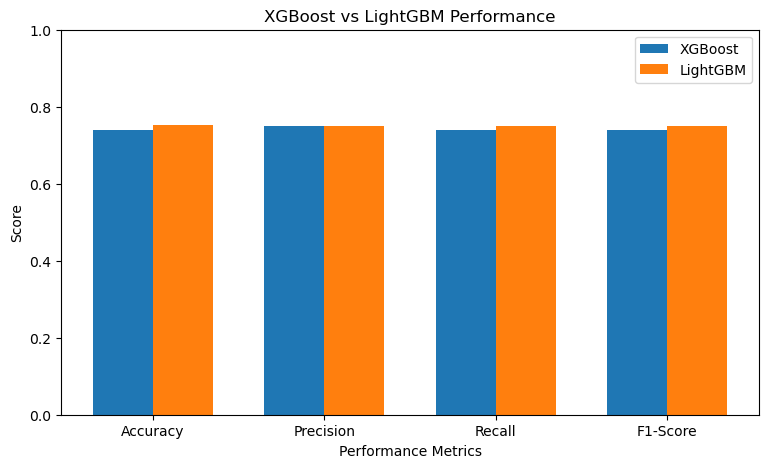

In [38]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']


xgb_scores = [0.7403, 0.75, 0.74, 0.74]

# LightGBM results
lgbm_scores = [0.7532, 0.75, 0.75, 0.75]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, xgb_scores, width, label='XGBoost')
plt.bar(x + width/2, lgbm_scores, width, label='LightGBM')

plt.xticks(x, metrics)
plt.ylabel('Score')
plt.xlabel('Performance Metrics')
plt.title('XGBoost vs LightGBM Performance')
plt.ylim(0, 1)
plt.legend()

plt.show()

### Observation

- XGBoost achieved an accuracy of 74.03%, while LightGBM achieved a slightly higher accuracy of 75.32%.
- Both models achieved similar precision, with XGBoost at 75% and LightGBM at 75%.
- LightGBM performed slightly better in recall and F1-score, achieving 75% compared to 74% for XGBoost.
- Both models performed better in predicting Class 0 than Class 1.
- The performance difference between the two models is small, indicating that both algorithms are suitable for the dataset.

### Conclusion

- LightGBM is the better-performing model overall because it achieved higher accuracy, recall, and F1-score.
- XGBoost also provided competitive and stable performance with only a small difference from LightGBM.
- Therefore, LightGBM can be selected as the preferred model for this dataset based on the test results.